## Customer Revenue, Risk & Retention Analytics Project

Project Objective

This project simulates a real-world analytics problem faced by e-commerce companies. Aanalyze
customer behavior, revenue patterns, returns, and delivery performance using Python and Pandas. The focus is
on logic building, data manipulation, and business insight generation.

## Import libraries and load datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
customers = pd.read_excel(r"C:\Users\bsush\Downloads\Task 01_Dataset.xlsx", sheet_name="customers")
orders = pd.read_excel(r"C:\Users\bsush\Downloads\Task 01_Dataset.xlsx", sheet_name="orders")
order_items = pd.read_excel(r"C:\Users\bsush\Downloads\Task 01_Dataset.xlsx", sheet_name="order_items")

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)

Customers: (600, 6)
Orders: (4000, 6)
Order Items: (9896, 5)


## Check missing values and order status

In [2]:
print("Customers missing values")
print(customers.isnull().sum())

print("\nOrders missing values")
print(orders.isnull().sum())

print("\nOrder_items missing values")
print(order_items.isnull().sum())

Customers missing values
customer_id        0
gender             0
age                0
city               0
signup_date        0
referral_source    0
dtype: int64

Orders missing values
order_id            0
customer_id         0
order_date          0
delivery_date    1165
order_status        0
payment_mode        0
dtype: int64

Order_items missing values
order_id      0
product_id    0
category      0
quantity      0
price         0
dtype: int64


In [3]:
print(pd.crosstab(
    orders['order_status'],
    orders['delivery_date'].isnull()
))

delivery_date  False  True 
order_status               
Cancelled          0    426
Delivered       2835      0
Returned           0    739


## Data cleaning and validation

In [4]:
print("Customers duplicates:", customers.duplicated().sum())
print("Orders duplicates:", orders.duplicated().sum())
print("Order Items duplicates:", order_items.duplicated().sum())

Customers duplicates: 0
Orders duplicates: 0
Order Items duplicates: 0


In [5]:
print(customers.dtypes)
print(orders.dtypes)
print(order_items.dtypes)

customer_id                 int64
gender                     object
age                         int64
city                       object
signup_date        datetime64[ns]
referral_source            object
dtype: object
order_id                  int64
customer_id               int64
order_date       datetime64[ns]
delivery_date    datetime64[ns]
order_status             object
payment_mode             object
dtype: object
order_id       int64
product_id     int64
category      object
quantity       int64
price          int64
dtype: object


In [6]:
print(orders['order_status'].value_counts())
print(orders['payment_mode'].value_counts())

order_status
Delivered    2835
Returned      739
Cancelled     426
Name: count, dtype: int64
payment_mode
UPI     1355
Card    1323
COD     1322
Name: count, dtype: int64


In [7]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['delivery_date'] = pd.to_datetime(orders['delivery_date'])

invalid_dates = orders[
    (orders['delivery_date'].notna()) &
    (orders['delivery_date'] < orders['order_date'])
]

print("Invalid delivery dates:", len(invalid_dates))

Invalid delivery dates: 0


In [8]:
order_summary = order_items.groupby('order_id').agg(
    quantity=('quantity', 'sum'),
    revenue=('price', lambda x: 0)  # Temporary placeholder
)

In [9]:
order_items['item_revenue'] = (
    order_items['quantity'] * order_items['price']
)

order_summary = order_items.groupby('order_id').agg(
    quantity=('quantity', 'sum'),
    order_value=('item_revenue', 'sum')
).reset_index()

print(order_summary.head())

   order_id  quantity  order_value
0     10001         1          798
1     10002         2         3030
2     10003         4         5208
3     10004        15        18980
4     10005         1         1522


In [10]:
merged_data = pd.merge(
    orders,
    order_summary,
    on='order_id',
    how='left'
)

print(merged_data.shape)

(4000, 8)


In [11]:
df = pd.merge(
    merged_data,
    customers,
    on='customer_id',
    how='left'
)

print(df.shape)
df.head()

(4000, 13)


,order_id,customer_id,order_date,delivery_date,order_status,payment_mode,quantity,order_value,gender,age,city,signup_date,referral_source
0,10001,183,2022-12-08,NaT,Returned,Card,1,798,Female,20,Bangalore,2022-10-11,Agent
1,10002,592,2023-06-03,NaT,Returned,COD,2,3030,Male,44,Chennai,2021-07-27,Agent
2,10003,464,2023-05-17,2023-05-26,Delivered,COD,4,5208,Male,23,Hyderabad,2022-01-16,App
3,10004,192,2023-06-18,2023-06-24,Delivered,COD,15,18980,Male,29,Chennai,2022-03-06,Agent
4,10005,310,2023-09-29,2023-10-04,Delivered,UPI,1,1522,Female,33,Pune,2021-09-04,App


In [12]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("Missing values:")
print(df.isnull().sum())

print("Unique orders:", df['order_id'].nunique())
print("Unique customers:", df['customer_id'].nunique())

Rows: 4000
Columns: 13
Missing values:
order_id              0
customer_id           0
order_date            0
delivery_date      1165
order_status          0
payment_mode          0
quantity              0
order_value           0
gender                0
age                   0
city                  0
signup_date           0
referral_source       0
dtype: int64
Unique orders: 4000
Unique customers: 600


## Create order_value using a custom function

In [17]:
def calculate_order_value(row):
    return row['quantity'] * row['price']

order_items['item_revenue'] = order_items.apply(
    calculate_order_value,
    axis=1
)

In [18]:
order_summary = order_items.groupby('order_id').agg(
    quantity=('quantity', 'sum'),
    order_value=('item_revenue', 'sum')
).reset_index()

In [19]:
df = df.drop(columns=['quantity', 'order_value'])

df = df.merge(
    order_summary,
    on='order_id',
    how='left'
)

print(df[['order_id', 'quantity', 'order_value']].head())

   order_id  quantity  order_value
0     10001         1          798
1     10002         2         3030
2     10003         4         5208
3     10004        15        18980
4     10005         1         1522


## Create delivery_delay_days

In [20]:
df['delivery_delay_days'] = (
    df['delivery_date'] - df['order_date']
).dt.days

print(df[['order_date', 'delivery_date',
          'delivery_delay_days']].head(10))

  order_date delivery_date  delivery_delay_days
0 2022-12-08           NaT                  NaN
1 2023-06-03           NaT                  NaN
2 2023-05-17    2023-05-26                  9.0
3 2023-06-18    2023-06-24                  6.0
4 2023-09-29    2023-10-04                  5.0
5 2023-04-16    2023-04-22                  6.0
6 2023-06-14    2023-06-22                  8.0
7 2022-08-29    2022-08-30                  1.0
8 2023-07-29    2023-08-01                  3.0
9 2024-02-02    2024-02-09                  7.0


## Customer behaviour columns is_repeat_customer – using lambda

In [21]:
customer_order_count = df.groupby('customer_id')['order_id'].transform('count')

df['is_repeat_customer'] = customer_order_count.apply(
    lambda x: True if x > 1 else False
)

print(df[['customer_id', 'is_repeat_customer']].head(10))

   customer_id  is_repeat_customer
0          183                True
1          592                True
2          464                True
3          192                True
4          310                True
5          263                True
6           24                True
7           22                True
8          292                True
9          103               False


## is_high_value_order – using lambda

In [22]:
df['is_high_value_order'] = df['order_value'].apply(
    lambda x: True if x > 3000 else False
)

print(df[['order_value', 'is_high_value_order']].head(10))

   order_value  is_high_value_order
0          798                False
1         3030                 True
2         5208                 True
3        18980                 True
4         1522                False
5         1301                False
6         8078                 True
7        20842                 True
8         4729                 True
9         5332                 True


## Customer value segmentation – using if–else

In [41]:
customer_revenue = df.groupby('customer_id')['order_value'].sum()

print(customer_revenue.head(10))

customer_id
1      86731
2      28657
3      39600
4     139057
5      76290
6      42727
7      70238
8      56318
9      69551
10     82955
Name: order_value, dtype: int64


In [42]:
print(customer_revenue.describe())

count       600.000000
mean      65630.338333
std       32216.767300
min        1272.000000
25%       42373.250000
50%       62930.500000
75%       83659.000000
max      205557.000000
Name: order_value, dtype: float64


In [43]:
lower_limit = customer_revenue.quantile(0.33)
upper_limit = customer_revenue.quantile(0.67)

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: 48230.840000000004
Upper limit: 77082.94


In [50]:
def customer_segment(revenue):

    if revenue <= lower_limit:
        return 'Low'

    elif revenue <= upper_limit:
        return 'Medium'

    else:
        return 'High'

In [46]:
customer_segments = customer_revenue.apply(customer_segment)

print(customer_segments.head(10))

customer_id
1       High
2        Low
3        Low
4       High
5     Medium
6        Low
7     Medium
8     Medium
9     Medium
10      High
Name: order_value, dtype: object


In [47]:
df['customer_value_segment'] = df['customer_id'].map(
    customer_segments
)

print(df[['customer_id', 'order_value',
          'customer_value_segment']].head(10))

   customer_id  order_value customer_value_segment
0          183          798                    Low
1          592         3030                 Medium
2          464         5208                 Medium
3          192        18980                 Medium
4          310         1522                    Low
5          263         1301                 Medium
6           24         8078                    Low
7           22        20842                   High
8          292         4729                    Low
9          103         5332                    Low


In [48]:
segment_analysis = df.groupby('customer_value_segment').agg(
    customer_count=('customer_id', 'nunique'),
    total_orders=('order_id', 'count'),
    gross_order_value=('order_value', 'sum')
).reset_index()

print(segment_analysis)

  customer_value_segment  customer_count  total_orders  gross_order_value
0                   High             198          1812           20128543
1                    Low             198           831            6445884
2                 Medium             204          1357           12803776


## Create customer_risk_category

In [51]:
customer_risk = df.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    returned_orders=('order_status', 
                     lambda x: (x == 'Returned').sum())
).reset_index()

customer_risk.head(10)

,customer_id,total_orders,returned_orders
0,1,5,3
1,2,4,1
2,3,7,0
3,4,11,3
4,5,7,3
5,6,6,1
6,7,6,1
7,8,5,0
8,9,6,3
9,10,7,1


In [52]:
customer_risk['return_rate'] = (
    customer_risk['returned_orders'] /
    customer_risk['total_orders']
) * 100

customer_risk.head(10)

,customer_id,total_orders,returned_orders,return_rate
0,1,5,3,60.000000
1,2,4,1,25.000000
2,3,7,0,0.000000
3,4,11,3,27.272727
4,5,7,3,42.857143
5,6,6,1,16.666667
6,7,6,1,16.666667
7,8,5,0,0.000000
8,9,6,3,50.000000
9,10,7,1,14.285714


In [53]:
risk_categories = []

for rate in customer_risk['return_rate']:

    if rate >= 30:
        risk_categories.append('High Risk')

    elif rate >= 15:
        risk_categories.append('Medium Risk')

    else:
        risk_categories.append('Low Risk')

customer_risk['risk_category'] = risk_categories

customer_risk.head(10)

,customer_id,total_orders,returned_orders,return_rate,risk_category
0,1,5,3,60.000000,High Risk
1,2,4,1,25.000000,Medium Risk
2,3,7,0,0.000000,Low Risk
3,4,11,3,27.272727,Medium Risk
4,5,7,3,42.857143,High Risk
5,6,6,1,16.666667,Medium Risk
6,7,6,1,16.666667,Medium Risk
7,8,5,0,0.000000,Low Risk
8,9,6,3,50.000000,High Risk
9,10,7,1,14.285714,Low Risk


In [54]:
risk_summary = customer_risk.groupby('risk_category').agg(
    customer_count=('customer_id', 'count'),
    total_returned_orders=('returned_orders', 'sum'),
    average_return_rate=('return_rate', 'mean')
).reset_index()

print(risk_summary)

  risk_category  customer_count  total_returned_orders  average_return_rate
0     High Risk             133                    334            43.014625
1      Low Risk             280                    103             4.377550
2   Medium Risk             187                    302            22.068925


In [55]:
df['risk_category'] = df['customer_id'].map(
    customer_risk.set_index('customer_id')['risk_category']
)

df[['customer_id', 'order_id', 'risk_category']].head(10)

,customer_id,order_id,risk_category
0,183,10001,High Risk
1,592,10002,High Risk
2,464,10003,Medium Risk
3,192,10004,Low Risk
4,310,10005,Low Risk
5,263,10006,Low Risk
6,24,10007,Low Risk
7,22,10008,Low Risk
8,292,10009,Low Risk
9,103,10010,Low Risk


## Create order_reliability_score

In [60]:
df['order_reliability_score'] = df['order_status'].apply(
    calculate_reliability
)

df[['order_status', 'order_reliability_score']].head(10)

,order_status,order_reliability_score
0,Returned,-1
1,Returned,-1
2,Delivered,1
3,Delivered,1
4,Delivered,1
5,Delivered,1
6,Delivered,1
7,Delivered,1
8,Delivered,1
9,Delivered,1


In [61]:
reliability_summary = df.groupby(
    'order_status'
).agg(
    total_orders=('order_id', 'count'),
    total_reliability_score=('order_reliability_score', 'sum'),
    average_reliability_score=('order_reliability_score', 'mean')
).reset_index()

print(reliability_summary)

  order_status  total_orders  total_reliability_score  \
0    Cancelled           426                     -852   
1    Delivered          2835                     2835   
2     Returned           739                     -739   

   average_reliability_score  
0                       -2.0  
1                        1.0  
2                       -1.0  


## Verify all seven mandatory columns

In [59]:
mandatory_columns = [
    'order_value',
    'delivery_delay_days',
    'is_repeat_customer',
    'is_high_value_order',
    'customer_value_segment',
    'customer_risk_category',
    'order_reliability_score'
]

print(df[mandatory_columns].head())

print("\nMissing values:")
print(df[mandatory_columns].isnull().sum())

   order_value  delivery_delay_days  is_repeat_customer  is_high_value_order  \
0          798                  NaN                True                False   
1         3030                  NaN                True                 True   
2         5208                  9.0                True                 True   
3        18980                  6.0                True                 True   
4         1522                  5.0                True                False   

  customer_value_segment customer_risk_category  order_reliability_score  
0                    Low                   High                       -1  
1                 Medium                   High                       -1  
2                 Medium                   High                        1  
3                 Medium                    Low                        1  
4                    Low                    Low                        1  

Missing values:
order_value                   0
delivery_delay_days 

In [31]:
print(df['customer_risk_category'].value_counts())

print(df['order_reliability_score'].value_counts())

customer_risk_category
High      1531
Medium    1422
Low       1047
Name: count, dtype: int64
order_reliability_score
 1    2835
-1     739
-2     426
Name: count, dtype: int64


## Business Question 1
## Q1 Which customers generate high revenue but have high return rates?

In [32]:
customer_analysis = df.groupby('customer_id').agg(
    total_revenue=('order_value', 'sum'),
    total_orders=('order_id', 'count'),
    returned_orders=(
        'order_status',
        lambda x: (x == 'Returned').sum()
    ),
    city=('city', 'first'),
    customer_segment=('customer_value_segment', 'first'),
    risk_category=('customer_risk_category', 'first')
).reset_index()

In [33]:
customer_analysis['return_rate'] = (
    customer_analysis['returned_orders'] /
    customer_analysis['total_orders']
) * 100

In [34]:
high_risk_customers = customer_analysis[
    (customer_analysis['total_revenue'] > 10000) &
    (customer_analysis['return_rate'] >= 30)
]

high_risk_customers = high_risk_customers.sort_values(
    by='total_revenue',
    ascending=False
)

print(high_risk_customers)

     customer_id  total_revenue  total_orders  returned_orders       city  \
76            77         137703            12                4    Chennai   
549          550         129900            12                4     Mumbai   
163          164         124676            10                3       Pune   
36            37         123272             8                3     Mumbai   
110          111         120005             9                4  Hyderabad   
..           ...            ...           ...              ...        ...   
433          434          16190             2                2     Mumbai   
54            55          15248             2                2  Bangalore   
459          460          14795             2                2      Delhi   
83            84          13131             2                1     Mumbai   
415          416          12009             5                2      Delhi   

    customer_segment risk_category  return_rate  
76              High     

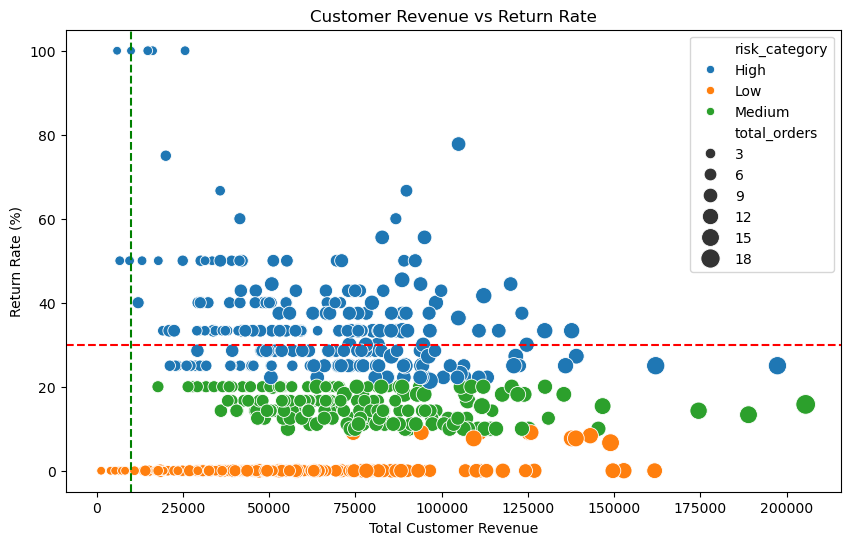

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_analysis,
    x='total_revenue',
    y='return_rate',
    hue='risk_category',
    size='total_orders',
    sizes=(40, 200)
)

plt.axhline(30, linestyle='--', color='red')
plt.axvline(10000, linestyle='--', color='green')

plt.title('Customer Revenue vs Return Rate')
plt.xlabel('Total Customer Revenue')
plt.ylabel('Return Rate (%)')

plt.show()

The analysis identified 129 customers who generate more than ₹10,000 in total order value but have return rates of 30% or higher. These customers represent a potential revenue risk. The business should investigate the reasons for their returns, identify recurring product or delivery issues, and introduce targeted retention strategies. Customers with very few orders should be monitored before being classified as consistently high-risk.

## Q2: Identify cities with delivery delays and revenue loss

In [31]:
city_analysis = df.groupby('city').agg(
    total_orders=('order_id', 'count'),

    delivered_orders=('order_status',
                      lambda x: (x == 'Delivered').sum()),

    returned_orders=('order_status',
                     lambda x: (x == 'Returned').sum()),

    cancelled_orders=('order_status',
                      lambda x: (x == 'Cancelled').sum()),

    average_delivery_days=('delivery_delay_days', 'mean'),

    returned_order_value=('order_value',
                          lambda x: x[df.loc[x.index, 'order_status'] == 'Returned'].sum()),

    cancelled_order_value=('order_value',
                           lambda x: x[df.loc[x.index, 'order_status'] == 'Cancelled'].sum())
).reset_index()

city_analysis['return_rate'] = (
    city_analysis['returned_orders'] /
    city_analysis['total_orders'] * 100
)

city_analysis['cancellation_rate'] = (
    city_analysis['cancelled_orders'] /
    city_analysis['total_orders'] * 100
)

print(city_analysis.round(2))

        city  total_orders  delivered_orders  returned_orders  \
0  Bangalore           720               524              132   
1    Chennai           737               520              138   
2      Delhi           612               434              100   
3  Hyderabad           599               413              122   
4     Mumbai           599               426              110   
5       Pune           733               518              137   

   cancelled_orders  average_delivery_days  returned_order_value  \
0                64                   4.93               1226184   
1                79                   5.04               1297103   
2                78                   4.98                971982   
3                64                   4.92               1219833   
4                63                   5.34               1086548   
5                78                   4.95               1299663   

   cancelled_order_value  return_rate  cancellation_rate  
0       

In [32]:
city_analysis['total_at_risk_value'] = (
    city_analysis['returned_order_value'] +
    city_analysis['cancelled_order_value']
)

city_analysis = city_analysis.sort_values(
    'total_at_risk_value',
    ascending=False
)

print(city_analysis[
    ['city', 'returned_order_value',
     'cancelled_order_value', 'total_at_risk_value']
])

        city  returned_order_value  cancelled_order_value  total_at_risk_value
5       Pune               1299663                 774768              2074431
1    Chennai               1297103                 760377              2057480
3  Hyderabad               1219833                 748299              1968132
0  Bangalore               1226184                 592484              1818668
2      Delhi                971982                 755801              1727783
4     Mumbai               1086548                 634257              1720805


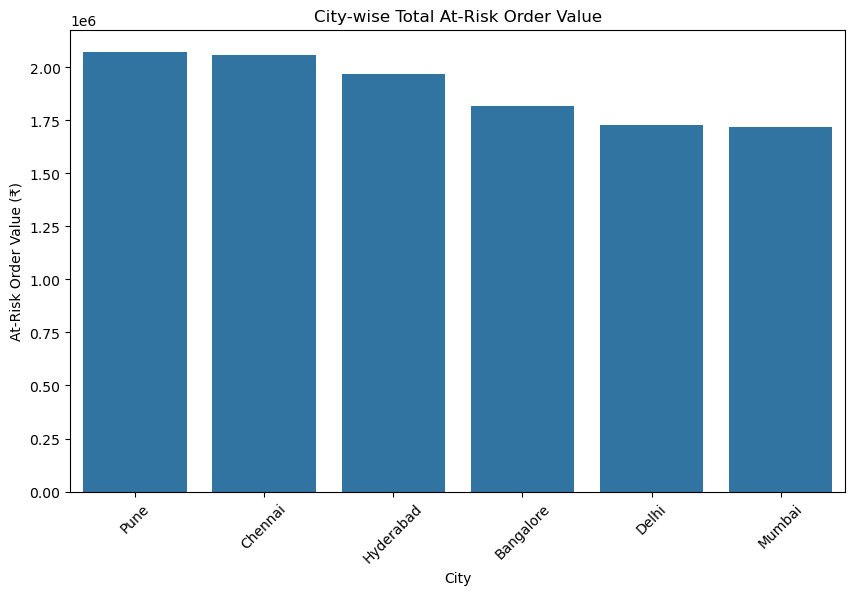

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_analysis,
    x='city',
    y='total_at_risk_value'
)

plt.title('City-wise Total At-Risk Order Value')
plt.xlabel('City')
plt.ylabel('At-Risk Order Value (₹)')
plt.xticks(rotation=45)

plt.show()

The city-wise analysis shows that Pune has the highest potential at-risk order value of ₹20,74,431, followed by Chennai at ₹20,57,480. Mumbai has the longest average order-to-delivery duration of 5.34 days, while Delhi has the highest cancellation rate of 12.75%. The business should investigate return and cancellation reasons in Pune and Chennai, improve delivery efficiency in Mumbai, and identify the causes of cancellations in Delhi.

## Q3 – Analyse repeat customer value

In [34]:
customer_type_analysis = df.groupby('is_repeat_customer').agg(
    total_customers=('customer_id', 'nunique'),
    total_orders=('order_id', 'count'),
    total_revenue=('order_value', 'sum'),
    average_order_value=('order_value', 'mean'),
    returned_orders=('order_status',
                     lambda x: (x == 'Returned').sum())
).reset_index()

customer_type_analysis['customer_type'] = (
    customer_type_analysis['is_repeat_customer']
    .map({True: 'Repeat Customers', False: 'One-time Customers'})
)

customer_type_analysis['return_rate'] = (
    customer_type_analysis['returned_orders'] /
    customer_type_analysis['total_orders'] * 100
)

print(customer_type_analysis.round(2))

   is_repeat_customer  total_customers  total_orders  total_revenue  \
0               False               13            13         103185   
1                True              587          3987       39275018   

   average_order_value  returned_orders       customer_type  return_rate  
0              7937.31                2  One-time Customers        15.38  
1              9850.77              737    Repeat Customers        18.49  


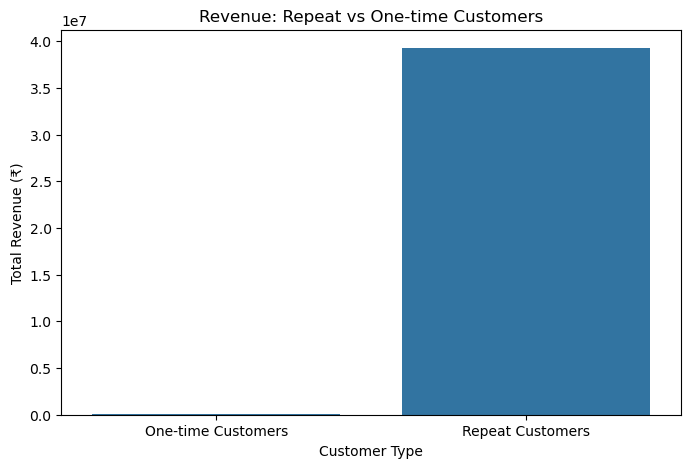

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_type_analysis,
    x='customer_type',
    y='total_revenue'
)

plt.title('Revenue: Repeat vs One-time Customers')
plt.xlabel('Customer Type')
plt.ylabel('Total Revenue (₹)')

plt.show()

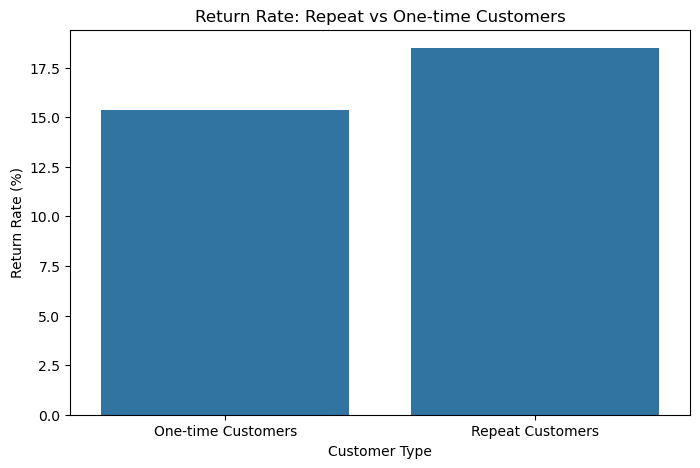

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_type_analysis,
    x='customer_type',
    y='return_rate'
)

plt.title('Return Rate: Repeat vs One-time Customers')
plt.xlabel('Customer Type')
plt.ylabel('Return Rate (%)')

plt.show()

The analysis shows that repeat customers generate approximately ₹3.93 crore in revenue, contributing around 99.7% of total revenue. Their average order value is ₹9,850.77, which is higher than that of one-time customers. However, repeat customers also have a higher return rate of 18.49%. The business should focus on retaining repeat customers while investigating return reasons to improve customer satisfaction and revenue.

## Q4: Identify product categories that generate high revenue but also have high returns.

In [37]:
print(order_items.columns)
print(order_items.head())

Index(['order_id', 'product_id', 'category', 'quantity', 'price',
       'item_revenue'],
      dtype='object')
   order_id  product_id category  quantity  price  item_revenue
0     10001         466    Books         1    798           798
1     10002         716     Home         2   1515          3030
2     10003         738     Home         4   1302          5208
3     10004         155    Books         3    716          2148
4     10004         919  Grocery         4   1166          4664


In [38]:
items_with_status = pd.merge(
    order_items,
    orders[['order_id', 'order_status']],
    on='order_id',
    how='left'
)

print(items_with_status.head())

   order_id  product_id category  quantity  price  item_revenue order_status
0     10001         466    Books         1    798           798     Returned
1     10002         716     Home         2   1515          3030     Returned
2     10003         738     Home         4   1302          5208    Delivered
3     10004         155    Books         3    716          2148    Delivered
4     10004         919  Grocery         4   1166          4664    Delivered


In [39]:
items_with_status['delivered_value'] = items_with_status['item_revenue'].where(
    items_with_status['order_status'] == 'Delivered', 0
)

items_with_status['returned_value'] = items_with_status['item_revenue'].where(
    items_with_status['order_status'] == 'Returned', 0
)

items_with_status['cancelled_value'] = items_with_status['item_revenue'].where(
    items_with_status['order_status'] == 'Cancelled', 0
)

items_with_status['returned_order_id'] = items_with_status['order_id'].where(
    items_with_status['order_status'] == 'Returned'
)

category_analysis = items_with_status.groupby('category').agg(
    total_revenue=('item_revenue', 'sum'),
    delivered_revenue=('delivered_value', 'sum'),
    returned_order_value=('returned_value', 'sum'),
    cancelled_order_value=('cancelled_value', 'sum'),
    total_orders=('order_id', 'nunique'),
    returned_orders=('returned_order_id', 'nunique')
).reset_index()

category_analysis['return_rate'] = (
    category_analysis['returned_orders'] /
    category_analysis['total_orders'] * 100
)

print(category_analysis.round(2))

      category  total_revenue  delivered_revenue  returned_order_value  \
0        Books        7938092            5664363               1323623   
1     Clothing        7968570            5617936               1471071   
2  Electronics        7998996            5618097               1502914   
3      Grocery        7789193            5554477               1446886   
4         Home        7683352            5556031               1356819   

   cancelled_order_value  total_orders  returned_orders  return_rate  
0                 950106          1610              276        17.14  
1                 879563          1667              310        18.60  
2                 877985          1646              309        18.77  
3                 787830          1654              293        17.71  
4                 770502          1567              282        18.00  


The category-wise analysis shows that Electronics generates the highest total order value of ₹79.99 lakh but also has the highest return rate of 18.77%. Clothing has the second-highest returned order value of ₹14.71 lakh. Books has the lowest return rate of 17.14%. The business should investigate product quality, descriptions and customer expectations in Electronics and Clothing to reduce returns while maintaining revenue.


## Q5 – Analyse payment mode risk

In [40]:
payment_analysis = df.groupby('payment_mode').agg(
    total_orders=('order_id', 'count'),

    delivered_orders=('order_status',
                      lambda x: (x == 'Delivered').sum()),

    returned_orders=('order_status',
                     lambda x: (x == 'Returned').sum()),

    cancelled_orders=('order_status',
                      lambda x: (x == 'Cancelled').sum()),

    returned_value=('order_value',
                    lambda x: x[df.loc[x.index, 'order_status'] == 'Returned'].sum()),

    cancelled_value=('order_value',
                     lambda x: x[df.loc[x.index, 'order_status'] == 'Cancelled'].sum())
).reset_index()

payment_analysis['return_rate'] = (
    payment_analysis['returned_orders'] /
    payment_analysis['total_orders'] * 100
)

payment_analysis['cancellation_rate'] = (
    payment_analysis['cancelled_orders'] /
    payment_analysis['total_orders'] * 100
)

payment_analysis['total_at_risk_value'] = (
    payment_analysis['returned_value'] +
    payment_analysis['cancelled_value']
)

print(payment_analysis.round(2))

  payment_mode  total_orders  delivered_orders  returned_orders  \
0          COD          1322               927              254   
1         Card          1323               961              224   
2          UPI          1355               947              261   

   cancelled_orders  returned_value  cancelled_value  return_rate  \
0               141         2483250          1431072        19.21   
1               138         2027341          1289021        16.93   
2               147         2590722          1545893        19.26   

   cancellation_rate  total_at_risk_value  
0              10.67              3914322  
1              10.43              3316362  
2              10.85              4136615  


The payment mode analysis shows that UPI has the highest potential at-risk order value of ₹41.37 lakh, followed by COD at ₹39.14 lakh. Card payments show the lowest return rate of 16.93% and the lowest at-risk value. The business should investigate the reasons behind UPI and COD returns and cancellations, while examining whether the smoother outcomes associated with card payments can provide useful insights.

## Visualisation 1: Monthly revenue trend

In [41]:
df['order_month'] = df['order_date'].dt.to_period('M')

monthly_revenue = df.groupby('order_month')['order_value'].sum().reset_index()

monthly_revenue['order_month'] = monthly_revenue['order_month'].astype(str)

print(monthly_revenue.head(10))

  order_month  order_value
0     2022-01      1892919
1     2022-02      1467486
2     2022-03      1588966
3     2022-04      1761310
4     2022-05      1489239
5     2022-06      1354406
6     2022-07      1600955
7     2022-08      1748129
8     2022-09      1672469
9     2022-10      1505835


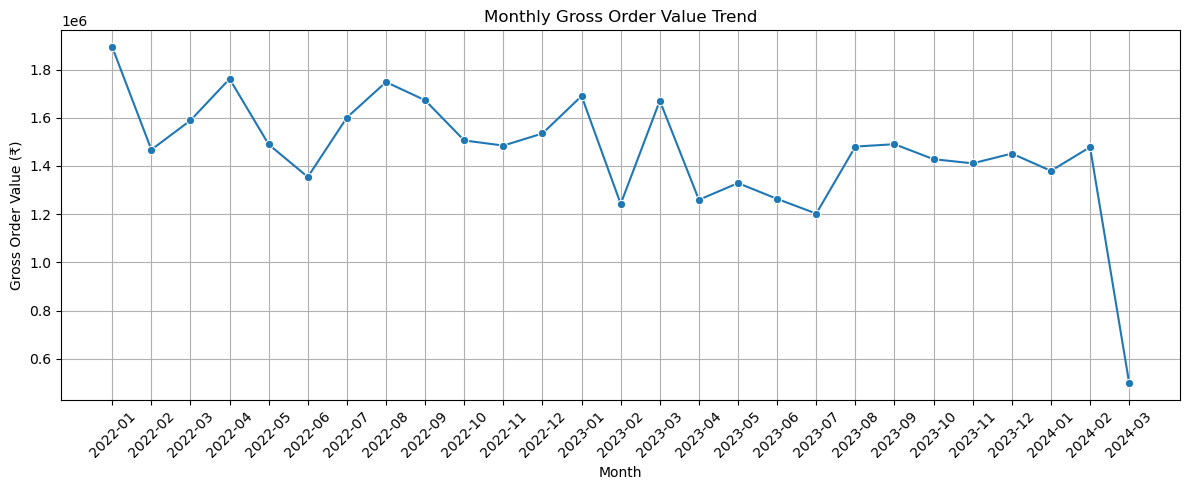

In [42]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x='order_month',
    y='order_value',
    marker='o'
)

plt.title('Monthly Gross Order Value Trend')
plt.xlabel('Month')
plt.ylabel('Gross Order Value (₹)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

Visualisation 1 – Observations
1. Highest month: January 2022, approximately ₹18.9 lakh.
2. Lowest month: March 2024, approximately ₹5 lakh.
3. Order value fluctuates considerably throughout 2022 and 2023.
4. There is a general decline during parts of 2023 compared with early 2022.
5. March 2024 shows a sharp drop. Check whether March contains a complete month's data before treating it as a business decline.
   
Business insight
Monthly gross order value shows considerable fluctuations, with the highest value recorded in January 2022. The trend declines during several periods in 2023. The business should investigate seasonal patterns and changes in order volume to understand these fluctuations.

## Visualisation 2 – Customer Value Segment

In [43]:
segment_analysis = df.groupby('customer_value_segment').agg(
    customer_count=('customer_id', 'nunique'),
    total_revenue=('order_value', 'sum')
).reset_index()

print(segment_analysis)

  customer_value_segment  customer_count  total_revenue
0                   High             587       39289229
1                    Low               2           5308
2                 Medium              11          83666


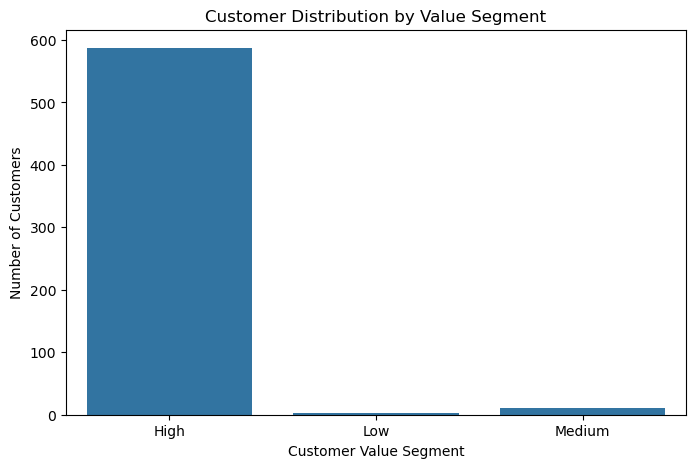

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x='customer_value_segment',
    y='customer_count'
)

plt.title('Customer Distribution by Value Segment')
plt.xlabel('Customer Value Segment')
plt.ylabel('Number of Customers')

plt.show()

Key observations
1. High-value customers: The majority of customers belong to the High segment (approximately 587 customers).
2. Medium-value customers: Only a small number of customers belong to this segment (approximately 10).
3. Low-value customers: Very few customers fall into the Low segment (approximately 3).
   
Business insight
The analysis shows that the majority of customers are classified as high-value customers, while only a small proportion belong to the Medium and Low segments. The business should focus on retaining high-value customers and developing targeted engagement strategies to increase the value of lower-segment customers.

## Visualisation 3 – Return Rate by Product Category.

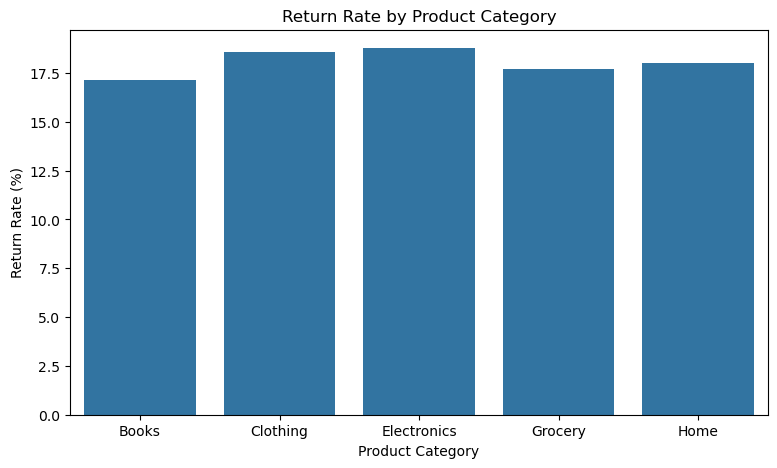

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x='category',
    y='return_rate'
)

plt.title('Return Rate by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Return Rate (%)')

plt.show()

Key observations
1. Electronics: Highest return rate at 18.77%, indicating the greatest return-related concern.
2. Clothing: Second-highest return rate at 18.60%.
3. Home: Return rate is 18.00%.
4. Grocery: Return rate is 17.71%.
5. Books: Lowest return rate at 17.14%, making it the best-performing category in terms of returns.

Business insight
The analysis shows that Electronics has the highest return rate of 18.77%, followed by Clothing at 18.60%. Books has the lowest return rate at 17.14%. The business should investigate product quality, product descriptions and customer expectations in Electronics and Clothing to reduce returns and improve customer satisfaction.

## Visualisation 4 – Delivery Duration vs Order Value.

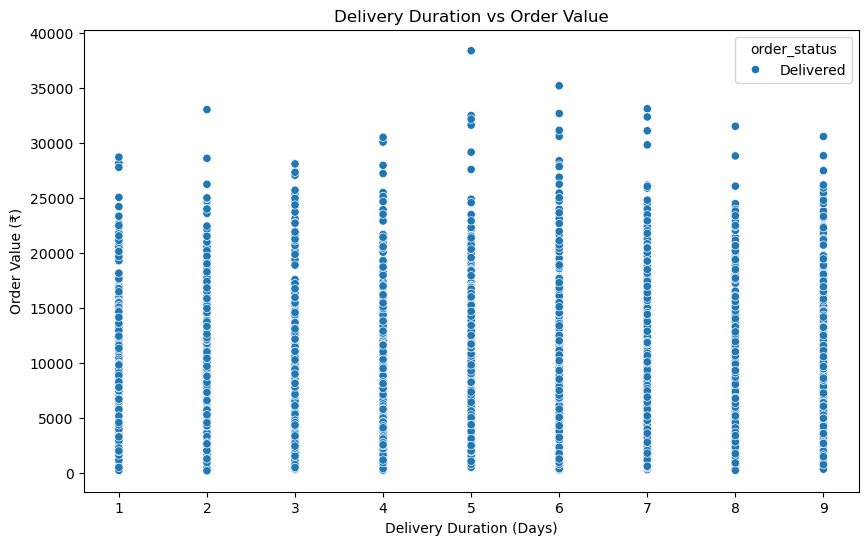

In [46]:
delivery_data = df[df['delivery_delay_days'].notna()]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=delivery_data,
    x='delivery_delay_days',
    y='order_value',
    hue='order_status'
)

plt.title('Delivery Duration vs Order Value')
plt.xlabel('Delivery Duration (Days)')
plt.ylabel('Order Value (₹)')

plt.show()

Key observations
1. Delivery duration: Orders were delivered within 1–9 days.
2. Most common order values: Many orders are concentrated below ₹20,000 across different delivery durations.
3. High-value orders: Some orders above ₹30,000 were delivered within 2–9 days.
4. No clear relationship: High-value orders are not consistently taking longer to deliver.
5. Outliers: A few orders have values above ₹30,000, including one around ₹38,500 delivered in 5 days.
   
Business insight
The analysis shows that delivery duration ranges from 1 to 9 days. High-value orders are distributed across different delivery durations, indicating no obvious relationship between order value and delivery time. The business should monitor orders with longer delivery durations and investigate factors affecting delivery efficiency.

## Visualisation 5 – City vs Category Revenue Heatmap

In [47]:
city_category_data = pd.merge(
    items_with_status,
    orders[['order_id', 'customer_id']],
    on='order_id',
    how='left'
)

city_category_data = pd.merge(
    city_category_data,
    customers[['customer_id', 'city']],
    on='customer_id',
    how='left'
)

In [48]:
city_category_revenue = city_category_data.pivot_table(
    index='city',
    columns='category',
    values='item_revenue',
    aggfunc='sum'
)

print(city_category_revenue)

category     Books  Clothing  Electronics  Grocery     Home
city                                                       
Bangalore  1403442   1355794      1476464  1316850  1305498
Chennai    1359866   1540417      1453545  1467090  1401516
Delhi      1390326   1127679      1236350  1356122  1169287
Hyderabad  1163142   1253782      1137370  1080157  1198947
Mumbai     1267306   1196176      1299283  1132148  1240416
Pune       1354010   1494722      1395984  1436826  1367688


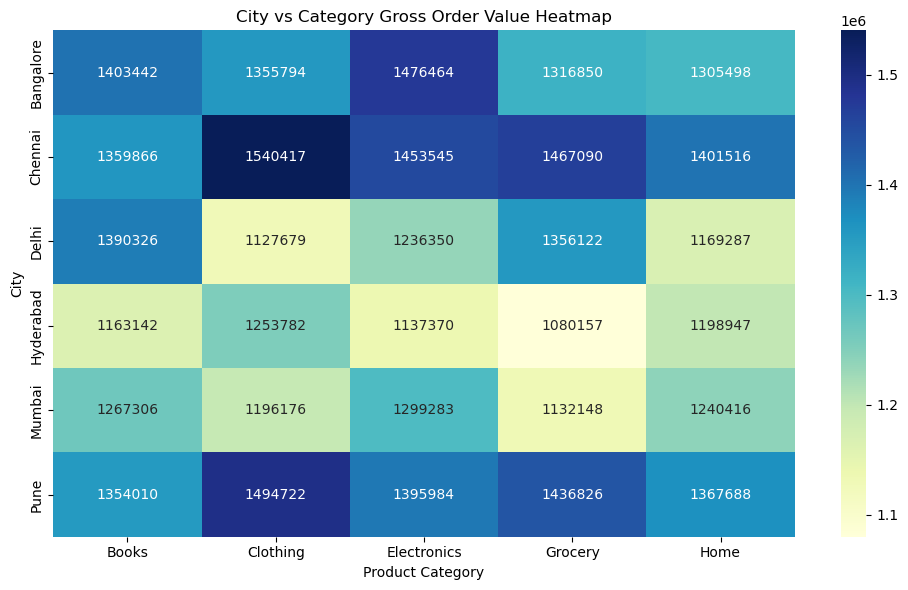

In [49]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    city_category_revenue,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('City vs Category Gross Order Value Heatmap')
plt.xlabel('Product Category')
plt.ylabel('City')

plt.tight_layout()
plt.show()

Key observations
1. Bangalore: Electronics generates the highest order value (₹14,76,464).
2. Chennai: Clothing performs best, generating ₹15,40,417.
3. Delhi: Books generates the highest order value (₹13,90,326).
4. Hyderabad: Clothing leads with ₹12,53,782.
5. Mumbai: Electronics has the highest order value (₹12,99,283).
6. Pune: Clothing generates the highest order value (₹14,94,722).
   
Business insight
The heatmap highlights differences in product category performance across cities. Clothing performs particularly well in Chennai, Hyderabad and Pune, while Electronics leads in Bangalore and Mumbai. Books generates the highest order value in Delhi. The business can use these insights to develop city-specific marketing strategies, optimise inventory allocation and target promotions based on customer demand.

## Customer Revenue, Risk & Retention Analysis


1. Three major business problems identified

Problem 1: High-value customers with high return rates

The analysis identified 129 customers with total order value above ₹10,000 and return rates of 30% or higher. These customers represent a potential revenue risk.

Problem 2: City-wise order value at risk

Pune has the highest combined returned and cancelled order value of ₹20,74,431, followed by Chennai at ₹20,57,480. Mumbai also has the longest average order-to-delivery duration at 5.34 days.

Problem 3: Product category and payment-related risks

Electronics has the highest category return rate (18.77%). UPI has the highest payment-mode return rate (19.26%) and the highest potential at-risk order value (₹41,36,615).

2. Three data-backed business recommendations

Recommendation 1: Improve customer retention
- Investigate why high-value customers frequently return orders.
- Identify repeated return patterns.
- Introduce targeted customer retention strategies.
Recommendation 2: Improve delivery and order management
- Investigate returned and cancelled orders in Pune and Chennai.
- Improve delivery efficiency in Mumbai.
- Study the reasons behind Delhi's high cancellation rate of 12.75%.
Recommendation 3: Reduce product and payment-related returns
- Investigate product quality and customer expectations in Electronics and Clothing.
- Analyse UPI and COD return and cancellation patterns.
- Improve product descriptions and order verification processes.

3. Overall project conclusion

The project analysed customer behaviour, order value, delivery performance, product categories and payment methods using Python and data analysis techniques.

The analysis identified important patterns in customer retention, returns, cancellations and city-wise performance. These findings can help businesses make data-driven decisions, reduce potential revenue losses, improve customer satisfaction and strengthen operational efficiency.

4. Tools and technologies used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook